In [13]:

import pandas as pd
import numpy as np
import os

DATA_FILE = "../ObesityDataset_raw_and_data_sinthetic.csv"

df = pd.read_csv(DATA_FILE)

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

print("\nData types and missing values:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())


Dataset loaded successfully!
Rows and columns: (2111, 17)

Column names:
['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS', 'NObeyesdad']

First five records:


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II



Data types and missing values:
<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   str    
 1   Age                             2111 non-null   int64  
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   str    
 5   FAVC                            2111 non-null   str    
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   str    
 9   SMOKE                           2111 non-null   str    
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   str    
 12  FAF          

In [14]:

# Confirm the target exists
target_column = "NObeyesdad"

if target_column not in df.columns:
    raise ValueError(
        f"Target '{target_column}' not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Remove exact duplicate rows for the initial analysis
df = df.drop_duplicates().copy()

# Remove records without a target
df = df.dropna(subset=[target_column]).copy()

# Separate input columns from the target
X = df.drop(columns=[target_column])
y = df[target_column].astype(str).str.strip()

print("Number of records:", len(df))
print("Number of input features:", X.shape[1])

print("\nTarget category counts:")
print(y.value_counts())

print("\nInput feature names:")
print(X.columns.tolist())


Number of records: 2087
Number of input features: 16

Target category counts:
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_II    290
Normal_Weight          282
Overweight_Level_I     276
Insufficient_Weight    267
Name: count, dtype: int64

Input feature names:
['Gender', 'Age', 'Height', 'Weight', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS']


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1669
Testing records: 418


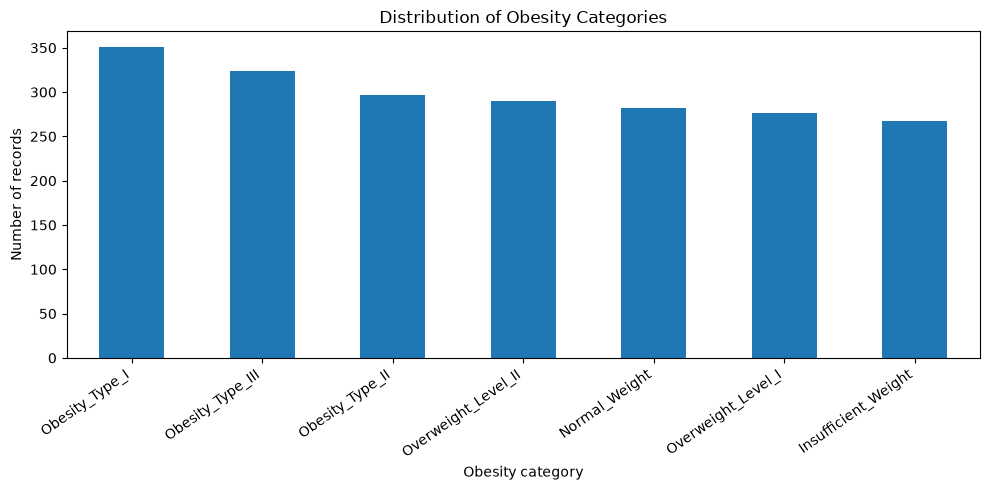

In [15]:

import matplotlib.pyplot as plt

category_counts = y.value_counts()

plt.figure(figsize=(10, 5))
category_counts.plot(kind="bar")
plt.title("Distribution of Obesity Categories")
plt.xlabel("Obesity category")
plt.ylabel("Number of records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [17]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42
    ),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(
        max_iter=5000,solver="saga", random_state=42
    )
}

print("Models ready for comparison:", list(models.keys()))


Models ready for comparison: ['Decision Tree', 'Random Forest', 'KNN', 'Logistic Regression']


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify categorical and numerical columns
categorical_columns = X_train.select_dtypes(
    include=["str", "category"]
).columns.tolist()

numerical_columns = X_train.select_dtypes(
    exclude=["str", "category"]
).columns.tolist()

# Create the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_columns),
        ("numerical", StandardScaler(), numerical_columns)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [22]:

import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from IPython.display import display as show_table

# Store trained models and their evaluation results
trained_models = {}
results = []

# Train and evaluate each model
for name, classifier in models.items():

    # Create a pipeline for each model
    model = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", clone(classifier))
    ])

    # Train the model
    model.fit(X_train, y_train)

    # Make predictions on test data
    predictions = model.predict(X_test)

    # Save the trained model
    trained_models[name] = model

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions,
            average="weighted",
            zero_division=0
        )
    })

# Create the comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

# Display results
show_table(results_df.round(4))

# Select the best-performing model
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\nModel training and comparison completed!")
print("Selected model:", best_model_name)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))


,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.9474,0.9476,0.9474,0.9473
1,Random Forest,0.9402,0.9428,0.9402,0.9408
2,Logistic Regression,0.8971,0.8948,0.8971,0.8952
3,KNN,0.8373,0.8306,0.8373,0.8229



Model training and comparison completed!
Selected model: Decision Tree
Training records: 1669
Testing records: 418


Best Model: Decision Tree

Classification Report:

                     precision    recall  f1-score   support

Insufficient_Weight       0.98      0.98      0.98        53
      Normal_Weight       0.93      0.95      0.94        57
     Obesity_Type_I       0.94      0.90      0.92        70
    Obesity_Type_II       0.95      0.97      0.96        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.91      0.89      0.90        55
Overweight_Level_II       0.92      0.97      0.94        58

           accuracy                           0.95       418
          macro avg       0.95      0.95      0.95       418
       weighted avg       0.95      0.95      0.95       418



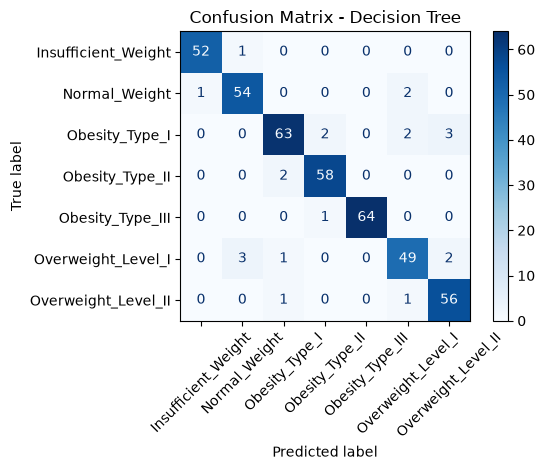

In [23]:

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict using the best-performing model
y_pred_best = best_model.predict(X_test)

# Display classification report
print("Best Model:", best_model_name)
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred_best,
    zero_division=0
))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()


In [24]:

import joblib

# Save the selected model and its details
joblib.dump({
    "model": best_model,
    "model_name": best_model_name,
    "feature_columns": X.columns.tolist(),
    "target_name": "NObeyesdad"
}, "obesity_model.joblib")

print("Best model saved successfully!")
print("Model:", best_model_name)


Best model saved successfully!
Model: Decision Tree
